# BLOQUE 3: Diseño, Optimización y Entrenamiento de Redes Neuronales Artificiales (RNA)
## Protocolo Experimental LOOCV ($N=24$), Modelos Directos y Residuales (*Residual-MLP*), Réplica Dr. Delgado y Estudio de Ablación

**Trabajo de Titulación para optar al título de Ingeniero Civil en Minas**  
**Universidad de Antofagasta** — Facultad de Ingeniería, Departamento de Ingeniería en Minas  

* **Autor:** Felipe Andrés Guerra Maturana  
* **Profesor Guía:** Dr. José Delgado Vega (*Doctor en Geología, Especialista en Geoestadística y Explotaciones Mineras, École des Mines de Paris*)  
* **Caso de Estudio:** Faena Mantos Cobrizo (Distrito Minero Los Cóndores) / ENAMI (Planta San José)  
* **Módulo:** Bloque 3 — Modelado Neuronal, Validación Cruzada LOOCV y Robustez  
* **Ubicación:** `./BLOQUE_3/`  
* **Versión Metodológica:** 4.0 (Línea Temporal Estricta — Cero Fuga, Rigor Econométrico y Auditoría Experta RCI)  

---

### Objetivos del Bloque 3:
1. **Reconstruir y auditar la réplica de referencia del profesor guía (Dr. José Delgado Vega)**:
   * Demostrar algebraicamente el colapso lineal de su arquitectura en TensorFlow/Keras ($57$ parámetros nominales, $P_{\text{eff}} = 3$ grados de libertad efectivos por omisión de función de activación no lineal).
   * Evaluar la red bajo el estándar riguroso fuera de muestra (**LOOCV**, $N = 24$), esclareciendo que el benchmark histórico del $8.63\%$ correspondió a una evaluación **MAPE in-sample** (cuyo NRMSE in-sample exacto fue $9.91\%$ sobre `PSJ_CuT` y $9.19\%$ sobre `Canje_CuT`).
2. **Explorar sistemáticamente una grilla parsimoniosa de perceptrones multicapa directos (`Direct-MLP`)**:
   * Evaluar topologías `(2,)`, `(3,)`, `(4,)`, `(2, 2)` y `(3, 2)` en Scikit-Learn con control estricto del ratio $N_{\text{train}} / P$.
3. **Implementar la familia de Redes con Aprendizaje Residual (*Residual-MLP* / Skip-Connection)**:
   * Formular la predicción como $\hat{y} = \text{Cancha\_CuT} - \hat{e}_{\text{MLP}}(\text{CuT}, \text{CuS})$, garantizando el colapso suave hacia `Baseline 1B` ($10.07\%$) bajo regularización $L_2$ (contracción $\Vert\mathbf{W}\Vert \to 0$) y evitando la atenuación de pendiente en frentes de alta ley (Noviembre 2023).
4. **Incorporar la batería exhaustiva de métricas de validación**:
   * Reportar el **Error Cuadrático Medio (MSE, en $(\%\text{Cu})^2$)**, junto a $\text{RMSE}$, $\text{MAE}$, $\text{NRMSE}\%$, $R^2$, $\text{MAPE}\%$, Pearson $r$, Sesgo Medio y Varianza Explicada.
5. **Ejecutar pruebas formales de robustez y ablación**:
   * Estudio de ablación (2D $[\text{CuT}, \text{CuS}]$ vs. 1D $[\text{CuT}]$).
   * Validación prospectiva simétrica (*Holdout* 19/5) contrastando con Cancha Directa, Baseline 1B ($8.96\%$ en la ventana), OLS y RidgeCV.
   * Sensibilidad geoestadística con *Buffered-LOOCV* justificando la adyacencia de Octubre y Noviembre 2023.
6. **Cumplir el contrato técnico de salida**:
   * Exportar `PREDICCIONES_OOS_RNA.csv/.xlsx`, `LOG_HIPERPARAMETROS_RNA.csv/.xlsx` y `SENSIBILIDAD_Y_ABLACION_RNA.csv/.xlsx` para la selección final e imparcial del *Champion Model* en el Bloque 4.

In [1]:
import os
import sys
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.neural_network import MLPRegressor
from sklearn.linear_model import LinearRegression, RidgeCV
from sklearn.preprocessing import StandardScaler
import tensorflow as tf

os.environ['TF_CPP_MIN_LOG_LEVEL'] = '3'
warnings.filterwarnings('ignore')

# Configuración de gráficos de publicación (200 DPI)
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['font.size'] = 10
plt.rcParams['figure.autolayout'] = True

print("Entorno computacional verificado para Bloque 3:")
print(f"NumPy: {np.__version__} | Pandas: {pd.__version__} | Scikit-Learn: 1.6+ | TensorFlow: {tf.__version__}")


Entorno computacional verificado para Bloque 3:
NumPy: 2.4.0 | Pandas: 2.3.3 | Scikit-Learn: 1.6+ | TensorFlow: 2.21.0


## 1. Fundamento Geometalúrgico y Carga del Dataset Auditado

Conforme a la **Teoría de Muestreo de Pierre Gy** y la zonación supergena de faena Mantos Cobrizo, el mineral extraído presenta heterogeneidad constitucional debida a la coexistencia de especies oxidadas (crisocola, malaquita, cuantificadas por la ley de cobre soluble $\text{CuS}$) y sulfuradas (calcocina, bornita, chalcopirita).

En Planta San José (ENAMI), los sulfuros flotan eficientemente, mientras que los óxidos sufren recuperaciones muy disminuidas. En consecuencia, el canje comercial depende fuertemente de la relación entre ambas leyes:
$$X = \begin{bmatrix} \text{Cancha\_CuT} & \text{Cancha\_CuS} \end{bmatrix} \in \mathbb{R}^{24 \times 2}, \qquad y = \text{Canje\_CuT} \in \mathbb{R}^{24 \times 1}$$

In [2]:
# Carga del dataset maestro auditado (Bloque 1)
df = pd.read_csv("../BLOQUE_1/DATASET_AUDITADO_N24.csv")
X_2d = df[['Cancha_CuT', 'Cancha_CuS']].values
X_1d = df[['Cancha_CuT']].values
y = df['Canje_CuT'].values
cancha = df['Cancha_CuT'].values
psj = df['PSJ_CuT'].values
fechas = df['Fecha'].values
N = len(y)

print(f"Dataset auditado cargado: N = {N} periodos mensuales.")
print(f"Media Canje_CuT = {np.mean(y):.5f} %Cu | Varianza Canje_CuT = {np.var(y):.6f} (%Cu)^2")
df[['Fecha', 'Cancha_CuT', 'Cancha_CuS', 'PSJ_CuT', 'Canje_CuT', 'Sesgo_Canje']].head()


Dataset auditado cargado: N = 24 periodos mensuales.
Media Canje_CuT = 1.43125 %Cu | Varianza Canje_CuT = 0.059436 (%Cu)^2


,Fecha,Cancha_CuT,Cancha_CuS,PSJ_CuT,Canje_CuT,Sesgo_Canje
0,2023-01,2.16,0.17,1.41,1.55,0.61
1,2023-02,1.76,0.14,1.33,1.41,0.35
2,2023-03,1.73,0.16,1.55,1.49,0.24
3,2023-04,1.66,0.14,1.38,1.38,0.28
4,2023-05,1.80,0.13,1.26,1.24,0.56


## 2. Caracterización de Arquitecturas: Réplica Dr. Delgado y Colapso Lineal

### 2.1. Demostración Algebraica del Colapso Lineal en Keras
El código original preservado de las presentaciones del Dr. José Delgado Vega (`Canje_carmenbajo_cobrizo_050325.ipynb`):
```python
capaEntrada = tf.keras.layers.Dense(units=4, input_shape=[2])
capaOculta1 = tf.keras.layers.Dense(units=4)
capaOculta2 = tf.keras.layers.Dense(units=4)
capaSalida  = tf.keras.layers.Dense(units=1)
modelo.compile(optimizer=tf.keras.optimizers.Adam(0.1), loss='mean_squared_error')
```
omite el argumento `activation`. En TensorFlow/Keras, el valor por defecto es activación lineal (identidad, $g(z) = z$).

El conteo paramétrico exacto para las dimensiones $[2 \to 4 \to 4 \to 4 \to 1]$ es:
* **Capa 1 (Entrada a Oculta 1):** $2 \times 4 + 4 = 12$
* **Capa 2 (Oculta 1 a Oculta 2):** $4 \times 4 + 4 = 20$
* **Capa 3 (Oculta 2 a Oculta 3):** $4 \times 4 + 4 = 20$
* **Capa 4 (Oculta 3 a Salida):** $4 \times 1 + 1 = 5$
* **Total Parámetros Nominales:** $12 + 20 + 20 + 5 = \mathbf{57}$ parámetros.

Por colapso asociativo de transformaciones afines:
$$\hat{y} = \mathbf{W}_4\Big(\mathbf{W}_3\big(\mathbf{W}_2(\mathbf{W}_1 \mathbf{x} + \mathbf{b}_1) + \mathbf{b}_2\big) + \mathbf{b}_3\Big) + b_4 = \mathbf{w}_{\text{eq}}^T \mathbf{x} + b_{\text{eq}}$$
Aunque la red posee $57$ parámetros nominales, **colapsa algebraicamente a una regresión lineal con exactamente $3$ grados de libertad efectivos ($P_{\text{eff}} = 3$)**. Esto explica rigurosamente por qué su comportamiento fuera de muestra replica casi a la perfección los baselines lineales (`OLS` y `RidgeCV`).

### 2.2. Esclarecimiento del Benchmark Histórico
El valor del Dr. Delgado de **$8.63\%$ en MECM** (y nuestro $7.97\%$) correspondió a una evaluación **MAPE in-sample** sobre `PSJ_CuT`. En términos de **NRMSE in-sample**, los valores exactos son **$9.91\%$** sobre `PSJ_CuT` ($0.1418 / 1.4304$) y **$9.19\%$** sobre `Canje_CuT` ($0.1315 / 1.4313$).

In [3]:
# Caracterización tabular de las arquitecturas evaluadas
topologias_info = [
    {"Modelo": "RNA_Delgado_Keras", "Familia": "Directa (Keras)", "Capas_Ocultas": "(4, 4, 4)", "Activacion": "linear (default)", "Parametros_Nom": 57, "P_Efectivos": 3, "Ratio_N_P": np.round(23/57, 2)},
    {"Modelo": "RNA_Delgado_MLP", "Familia": "Directa (MLP)", "Capas_Ocultas": "(4, 4)", "Activacion": "relu", "Parametros_Nom": 37, "P_Efectivos": 37, "Ratio_N_P": np.round(23/37, 2)},
    {"Modelo": "RNA_MLP_2", "Familia": "Directa (MLP)", "Capas_Ocultas": "(2,)", "Activacion": "tanh", "Parametros_Nom": 9, "P_Efectivos": 9, "Ratio_N_P": np.round(23/9, 2)},
    {"Modelo": "RNA_MLP_3", "Familia": "Directa (MLP)", "Capas_Ocultas": "(3,)", "Activacion": "relu", "Parametros_Nom": 13, "P_Efectivos": 13, "Ratio_N_P": np.round(23/13, 2)},
    {"Modelo": "RNA_MLP_4", "Familia": "Directa (MLP)", "Capas_Ocultas": "(4,)", "Activacion": "relu", "Parametros_Nom": 17, "P_Efectivos": 17, "Ratio_N_P": np.round(23/17, 2)},
    {"Modelo": "RNA_MLP_2_2", "Familia": "Directa (MLP)", "Capas_Ocultas": "(2, 2)", "Activacion": "relu", "Parametros_Nom": 15, "P_Efectivos": 15, "Ratio_N_P": np.round(23/15, 2)},
    {"Modelo": "RNA_MLP_3_2", "Familia": "Directa (MLP)", "Capas_Ocultas": "(3, 2)", "Activacion": "tanh", "Parametros_Nom": 20, "P_Efectivos": 20, "Ratio_N_P": np.round(23/20, 2)},
    {"Modelo": "Res_MLP_2", "Familia": "Residual-MLP", "Capas_Ocultas": "(2,)", "Activacion": "relu", "Parametros_Nom": 9, "P_Efectivos": 9, "Ratio_N_P": np.round(23/9, 2)},
    {"Modelo": "Res_MLP_2_2", "Familia": "Residual-MLP", "Capas_Ocultas": "(2, 2)", "Activacion": "relu", "Parametros_Nom": 15, "P_Efectivos": 15, "Ratio_N_P": np.round(23/15, 2)},
    {"Modelo": "Res_MLP_3", "Familia": "Residual-MLP", "Capas_Ocultas": "(3,)", "Activacion": "relu", "Parametros_Nom": 13, "P_Efectivos": 13, "Ratio_N_P": np.round(23/13, 2)},
    {"Modelo": "Res_MLP_4", "Familia": "Residual-MLP", "Capas_Ocultas": "(4,)", "Activacion": "relu", "Parametros_Nom": 17, "P_Efectivos": 17, "Ratio_N_P": np.round(23/17, 2)}
]

df_top = pd.DataFrame(topologias_info)
print("=== CARACTERIZACIÓN ESTRUCTURAL DE ARQUITECTURAS EVALUADAS ===")
df_top


=== CARACTERIZACIÓN ESTRUCTURAL DE ARQUITECTURAS EVALUADAS ===


,Modelo,Familia,Capas_Ocultas,Activacion,Parametros_Nom,P_Efectivos,Ratio_N_P
0,RNA_Delgado_Keras,Directa (Keras),"(4, 4, 4)",linear (default),57,3,0.40
1,RNA_Delgado_MLP,Directa (MLP),"(4, 4)",relu,37,37,0.62
2,RNA_MLP_2,Directa (MLP),"(2,)",tanh,9,9,2.56
3,RNA_MLP_3,Directa (MLP),"(3,)",relu,13,13,1.77
4,RNA_MLP_4,Directa (MLP),"(4,)",relu,17,17,1.35
5,RNA_MLP_2_2,Directa (MLP),"(2, 2)",relu,15,15,1.53
6,RNA_MLP_3_2,Directa (MLP),"(3, 2)",tanh,20,20,1.15
7,Res_MLP_2,Residual-MLP,"(2,)",relu,9,9,2.56
8,Res_MLP_2_2,Residual-MLP,"(2, 2)",relu,15,15,1.53
9,Res_MLP_3,Residual-MLP,"(3,)",relu,13,13,1.77


## 3. Redes Neuronales con Aprendizaje Residual (*Residual-Learning MLP*)

### 3.1. Diagnóstico del Error de Extrapolación en Noviembre 2023
En pliegues con frentes de alta ley anómalos como Noviembre 2023 (`Cancha_CuT = 2.47%`, `Canje_CuT = 2.27%`), las redes directas sufren saturación de activación (`tanh`) o contracción por regularización $L_2$, jalando la predicción hacia el promedio global de entrenamiento ($pprox 1.40\%$). En `RNA_MLP_2`, Nov-2023 concentró el $27.3\%$ de todo el error cuadrático acumulado del modelo.

### 3.2. Formulación Física de la Conexión Residual (*Skip-Connection*)
Inspirados en la ecuación de conciliación metalúrgica de Pierre Gy, se desacopla la ley base de la corrección geometalúrgica no lineal:
$$\hat{y}_k = \text{Cancha\_CuT}_k - \hat{e}_{\text{MLP}}(\text{Cancha\_CuT}_k,\; \text{Cancha\_CuS}_k)$$
donde el objetivo interno de entrenamiento de la red es el sesgo empírico:
$$e_i = \text{Cancha\_CuT}_i - \text{Canje\_CuT}_i, \qquad i \in \text{Train}_{-k}$$

**Propiedades Matemáticas y Operativas (Auditoría RCI):**
1. **Límite inferior garantizado:** Cuando la regularización $L_2$ (con $\alpha = 2.0$) contrae los pesos sinápticos $\Vert\mathbf{W}\Vert \to 0$, $\hat{e}_{\text{MLP}} \to \bar{e}_{\text{train},-k}$, colapsando de forma suave, exacta y robusta hacia **`Baseline 1B` ($10.07\%$)**. Esto constituye un activo metodológico en regímenes de muestra pequeña ($N=24$) para neutralizar el incremento de varianza inducido por frentes anómalos.
2. **Sin sesgo de extrapolación catastrófica:** En Noviembre 2023, la red residual preserva la ley de cancha base sin atenuar la pendiente.
3. **Implicación para el Bloque 4 (XAI e Interpretabilidad):** Dado que la regularización en `Residual-MLP` contrae los pesos hacia cero (haciendo que el aporte marginal de $\text{CuS}$ sea plano), la explicabilidad e interpretabilidad profunda (SHAP, Permutation Importance y Superficie de Respuesta 2D) **debe ejecutarse formalmente sobre `RNA_MLP_2`**, donde ambos predictores poseen pesos activos no nulos y la ley soluble $\text{CuS}$ reduce activamente el NRMSE en $-1.53\%$.

In [4]:
# Carga de las 24 predicciones ciegas cronológicas auditadas
df_preds = pd.read_csv("PREDICCIONES_OOS_RNA.csv")
print(f"Archivo PREDICCIONES_OOS_RNA.csv cargado exitosamente ({len(df_preds)} meses).")
df_preds.head(10)


Archivo PREDICCIONES_OOS_RNA.csv cargado exitosamente (24 meses).


,Fecha,Canje_CuT,Pred_RNA_Delgado_Keras,Pred_RNA_Delgado_MLP,Pred_RNA_MLP_2,Pred_RNA_MLP_3,Pred_RNA_MLP_4,Pred_RNA_MLP_2_2,Pred_RNA_MLP_3_2,Pred_Res_MLP_2,Pred_Res_MLP_2_2,Pred_Res_MLP_3,Pred_Res_MLP_4
0,2023-01,1.55,1.7934,1.7500,1.8128,1.6953,1.6954,1.6520,1.7600,1.8313,1.8313,1.8313,1.8313
1,2023-02,1.41,1.4140,1.4081,1.4187,1.4127,1.4126,1.4176,1.3981,1.4200,1.4200,1.4200,1.4200
2,2023-03,1.49,1.4090,1.4197,1.5501,1.4297,1.4307,1.4229,1.4190,1.3852,1.3852,1.3852,1.3852
3,2023-04,1.38,1.3353,1.3425,1.3224,1.3610,1.3618,1.3788,1.3566,1.3170,1.3170,1.3170,1.3170
4,2023-05,1.24,1.4499,1.4293,1.4482,1.4250,1.4251,1.4332,1.4092,1.4691,1.4691,1.4691,1.4691
5,2023-06,1.34,1.4140,1.4004,1.4155,1.4026,1.4026,1.4147,1.3859,1.4335,1.4335,1.4335,1.4335
6,2023-07,1.37,1.3956,1.3850,1.3907,1.3900,1.3899,1.4055,1.3749,1.4113,1.4113,1.4113,1.4113
7,2023-08,1.52,1.3600,1.3336,1.3306,1.3507,1.3499,1.3754,1.3366,1.3943,1.3944,1.3943,1.3943
8,2023-09,1.55,1.5913,1.4999,1.3739,1.4942,1.4927,1.4941,1.4411,1.6748,1.6748,1.6748,1.6748
9,2023-10,1.79,2.0738,2.0801,1.8532,2.0568,2.0418,1.8559,1.8985,1.8730,1.8730,1.8730,1.8730


## 4. Desempeño Fuera de Muestra (LOOCV, $N = 24$)

A continuación se calcula la batería exhaustiva de indicadores de desempeño sobre las **24 predicciones del ensamble multi-semilla**, incorporando de manera explícita el **Error Cuadrático Medio (MSE, en $(\%\text{Cu})^2$)**:
$$\text{MSE} = \frac{1}{N}\sum_{k=1}^N (y_k - \hat{y}_k)^2, \qquad \text{RMSE} = \sqrt{\text{MSE}}, \qquad \text{NRMSE} = \frac{\text{RMSE}}{\bar{y}} \times 100\%$$

In [5]:
# Cálculo de indicadores directamente sobre el vector de predicciones OOS
y_true = df_preds['Canje_CuT'].values
mean_y = np.mean(y_true)
sst = np.sum((y_true - mean_y)**2)

metrics_list = []
pred_cols = [c for c in df_preds.columns if c.startswith('Pred_')]

for col in pred_cols:
    mname = col.replace('Pred_', '')
    yp = df_preds[col].values
    err = y_true - yp
    
    mse = np.mean(err**2)
    rmse = np.sqrt(mse)
    mae = np.mean(np.abs(err))
    nrmse = (rmse / mean_y) * 100
    r2 = 1 - (np.sum(err**2) / sst)
    mape = np.mean(np.abs(err / y_true)) * 100
    r_pearson = np.corrcoef(y_true, yp)[0, 1]
    bias = np.mean(yp - y_true)
    var_exp = 1 - (np.var(err) / np.var(y_true))
    
    # Metadata
    fam = "Residual-MLP" if "Res_" in mname else ("Directa (Keras)" if "Keras" in mname else "Directa (MLP)")
    
    metrics_list.append({
        'Modelo': mname,
        'Familia': fam,
        'MSE (%Cu)^2': np.round(mse, 6),
        'RMSE (%Cu)': np.round(rmse, 4),
        'MAE (%Cu)': np.round(mae, 4),
        'NRMSE (%)': np.round(nrmse, 2),
        'R2 Score': np.round(r2, 4),
        'MAPE (%)': np.round(mape, 2),
        'Pearson r': np.round(r_pearson, 4),
        'Sesgo (%Cu)': np.round(bias, 4),
        'Var Explicada': np.round(var_exp, 4)
    })

df_metrics = pd.DataFrame(metrics_list).sort_values('RMSE (%Cu)')
print("=== TABLA 4.1: DESEMPEÑO PREDICTIVO FUERA DE MUESTRA (LOOCV, N=24) ===")
df_metrics


=== TABLA 4.1: DESEMPEÑO PREDICTIVO FUERA DE MUESTRA (LOOCV, N=24) ===


,Modelo,Familia,MSE (%Cu)^2,RMSE (%Cu),MAE (%Cu),NRMSE (%),R2 Score,MAPE (%),Pearson r,Sesgo (%Cu),Var Explicada
9,Res_MLP_3,Residual-MLP,0.020782,0.1442,0.1178,10.07,0.6503,8.12,0.8209,-0.0000,0.6503
10,Res_MLP_4,Residual-MLP,0.020782,0.1442,0.1178,10.07,0.6503,8.12,0.8209,-0.0000,0.6503
8,Res_MLP_2_2,Residual-MLP,0.020781,0.1442,0.1177,10.07,0.6504,8.12,0.8209,0.0000,0.6504
7,Res_MLP_2,Residual-MLP,0.021551,0.1468,0.1200,10.26,0.6374,8.22,0.8103,-0.0022,0.6375
0,RNA_Delgado_Keras,Directa (Keras),0.027735,0.1665,0.1302,11.64,0.5334,8.74,0.7410,0.0022,0.5334
2,RNA_MLP_2,Directa (MLP),0.030890,0.1758,0.1318,12.28,0.4803,8.95,0.6954,-0.0124,0.4829
4,RNA_MLP_4,Directa (MLP),0.031446,0.1773,0.1340,12.39,0.4709,9.15,0.6867,0.0060,0.4715
3,RNA_MLP_3,Directa (MLP),0.031951,0.1787,0.1350,12.49,0.4624,9.23,0.6809,0.0068,0.4632
1,RNA_Delgado_MLP,Directa (MLP),0.032592,0.1805,0.1378,12.61,0.4516,9.33,0.6778,0.0001,0.4516
5,RNA_MLP_2_2,Directa (MLP),0.034635,0.1861,0.1300,13.00,0.4173,8.92,0.6683,0.0009,0.4173


### 4.2. Tabla de Predicciones OOS Mes a Mes ($N = 24$)
Verificación de coincidencia absoluta entre las predicciones del modelo y las métricas computadas:

In [6]:
# Despliegue de las 24 predicciones cronológicas completas
pd.set_option('display.max_columns', None)
pd.set_option('display.width', 1000)
print("=== TABLA 4.2: PREDICCIONES OOS CRONOLÓGICAS COMPLETAS (N=24) ===")
df_preds


=== TABLA 4.2: PREDICCIONES OOS CRONOLÓGICAS COMPLETAS (N=24) ===


,Fecha,Canje_CuT,Pred_RNA_Delgado_Keras,Pred_RNA_Delgado_MLP,Pred_RNA_MLP_2,Pred_RNA_MLP_3,Pred_RNA_MLP_4,Pred_RNA_MLP_2_2,Pred_RNA_MLP_3_2,Pred_Res_MLP_2,Pred_Res_MLP_2_2,Pred_Res_MLP_3,Pred_Res_MLP_4
0,2023-01,1.55,1.7934,1.7500,1.8128,1.6953,1.6954,1.6520,1.7600,1.8313,1.8313,1.8313,1.8313
1,2023-02,1.41,1.4140,1.4081,1.4187,1.4127,1.4126,1.4176,1.3981,1.4200,1.4200,1.4200,1.4200
2,2023-03,1.49,1.4090,1.4197,1.5501,1.4297,1.4307,1.4229,1.4190,1.3852,1.3852,1.3852,1.3852
3,2023-04,1.38,1.3353,1.3425,1.3224,1.3610,1.3618,1.3788,1.3566,1.3170,1.3170,1.3170,1.3170
4,2023-05,1.24,1.4499,1.4293,1.4482,1.4250,1.4251,1.4332,1.4092,1.4691,1.4691,1.4691,1.4691
5,2023-06,1.34,1.4140,1.4004,1.4155,1.4026,1.4026,1.4147,1.3859,1.4335,1.4335,1.4335,1.4335
6,2023-07,1.37,1.3956,1.3850,1.3907,1.3900,1.3899,1.4055,1.3749,1.4113,1.4113,1.4113,1.4113
7,2023-08,1.52,1.3600,1.3336,1.3306,1.3507,1.3499,1.3754,1.3366,1.3943,1.3944,1.3943,1.3943
8,2023-09,1.55,1.5913,1.4999,1.3739,1.4942,1.4927,1.4941,1.4411,1.6748,1.6748,1.6748,1.6748
9,2023-10,1.79,2.0738,2.0801,1.8532,2.0568,2.0418,1.8559,1.8985,1.8730,1.8730,1.8730,1.8730


## 5. Estudio Experimental de Ablación de Entradas (2D vs. 1D)

Se compara el rendimiento del espacio bidimensional $[\text{CuT}, \text{CuS}]$ frente al unidimensional $[\text{CuT}]$ bajo el mismo bucle LOOCV, evaluando la variación en **MSE** y **NRMSE%**:

In [7]:
# Carga de la tabla de ablación auditada
df_abl = pd.read_excel("SENSIBILIDAD_Y_ABLACION_RNA.xlsx", sheet_name="Ablacion_Entradas")
print("=== TABLA 5.1: ESTUDIO DE ABLACIÓN DE ENTRADAS (2D vs. 1D) ===")
df_abl


=== TABLA 5.1: ESTUDIO DE ABLACIÓN DE ENTRADAS (2D vs. 1D) ===


,Modelo,Topologia,Entradas,Parametros,MSE,RMSE,MAE,NRMSE_%,R2
0,RNA_MLP_2,"(2,)","2D [CuT, CuS]",9,0.030890,0.175754,0.131846,12.279776,0.480288
1,RNA_MLP_2,"(2,)",1D [CuT],7,0.039068,0.197657,0.151402,13.810107,0.342681
2,RNA_MLP_3,"(3,)","2D [CuT, CuS]",13,0.031951,0.178749,0.135008,12.489039,0.462424
3,RNA_MLP_3,"(3,)",1D [CuT],10,0.031839,0.178435,0.134117,12.467080,0.464313
4,RNA_MLP_4,"(4,)","2D [CuT, CuS]",17,0.031446,0.177330,0.133958,12.389851,0.470929
5,RNA_MLP_4,"(4,)",1D [CuT],13,0.031462,0.177376,0.133764,12.393052,0.470656
6,RNA_MLP_2_2,"(2, 2)","2D [CuT, CuS]",15,0.034635,0.186103,0.130017,13.002863,0.417280
7,RNA_MLP_2_2,"(2, 2)",1D [CuT],13,0.037011,0.192382,0.136450,13.441565,0.377296
8,RNA_MLP_3_2,"(3, 2)","2D [CuT, CuS]",20,0.037222,0.192931,0.139821,13.479912,0.373738
9,RNA_MLP_3_2,"(3, 2)",1D [CuT],17,0.039217,0.198034,0.140714,13.836432,0.340173


## 6. Verificaciones de Robustez: Holdout 19/5 y *Buffered-LOOCV*

### 6.1. Validación Prospectiva Simétrica (*Holdout* Cronológico 19/5)
Para evitar comparaciones asimétricas, se evaluaron los 4 baselines principales del Bloque 2 (`Cancha Directa`, `Baseline 1B`, `OLS`, `RidgeCV`) sobre la **misma ventana de 5 meses** (`2024-08` a `2024-12`):
* En esta ventana, `Baseline 1B` alcanza $\text{NRMSE} = 8.96\%$ (no $10.07\%$, que corresponde a los 24 meses).
* `RNA_MLP_2` alcanza un extraordinario **$\text{NRMSE} = 6.56\%$** ($	ext{RMSE} = 0.0861\%\text{Cu}$), demostrando excelente estabilidad en producción sulfurada regular.

### 6.2. Sensibilidad Geoestadística (*Buffered-LOOCV*)
Al excluir $(t-1, t+1)$, `RNA_MLP_2` directa sube a $14.53\%$ ($+2.25\%$). La explicación técnica radica en que **Octubre 2023** ($t=10$) y **Noviembre 2023** ($t=11$) son **estrictamente contiguos en el tiempo**. Excluir los vecinos elimina simultáneamente el único soporte de alta ley disponible en la cola superior. Por su parte, la familia `Residual-MLP` permanece completamente blindada ($	ext{NRMSE} \approx 10.04\% - 10.21\%$).

In [8]:
# Lectura y visualización de Holdout y Buffered-LOOCV
df_holdout = pd.read_excel("SENSIBILIDAD_Y_ABLACION_RNA.xlsx", sheet_name="Holdout_19_5_Simetrico")
df_buf = pd.read_excel("SENSIBILIDAD_Y_ABLACION_RNA.xlsx", sheet_name="Buffered_LOOCV")

print("=== TABLA 6.1: VALIDACIÓN PROSPECTIVA HOLDOUT 19/5 SIMÉTRICA ===")
display(df_holdout)

print("\n=== TABLA 6.2: SENSIBILIDAD GEOESTADÍSTICA BUFFERED-LOOCV ===")
display(df_buf)


=== TABLA 6.1: VALIDACIÓN PROSPECTIVA HOLDOUT 19/5 SIMÉTRICA ===


,Modelo,Tipo,MSE_Holdout,RMSE_Holdout,MAE_Holdout,NRMSE_Holdout_%,R2_Holdout
0,RNA_MLP_2,Directa-MLP,0.007417,0.086123,0.074959,6.564284,0.654948
1,RidgeCV,Baseline,0.009875,0.099374,0.088041,7.574260,0.540601
2,OLS,Baseline,0.010362,0.101794,0.085930,7.758721,0.517952
3,Res_MLP_4,Residual-MLP,0.013804,0.117492,0.092104,8.955205,0.357814
4,Res_MLP_2_2,Residual-MLP,0.013804,0.117492,0.092105,8.955217,0.357812
5,Res_MLP_3,Residual-MLP,0.013804,0.117492,0.092105,8.955219,0.357812
6,Baseline 1B (Bias Corr),Baseline,0.013804,0.117492,0.092105,8.955221,0.357811
7,Res_MLP_2,Residual-MLP,0.013805,0.117493,0.092106,8.955236,0.357809
8,RNA_Delgado_MLP,Directa-MLP,0.016412,0.128108,0.112147,9.764342,0.236523
9,RNA_MLP_4,Directa-MLP,0.017881,0.133721,0.117373,10.192125,0.168161



=== TABLA 6.2: SENSIBILIDAD GEOESTADÍSTICA BUFFERED-LOOCV ===


,Modelo,Topologia,MSE_LOOCV,RMSE_LOOCV,NRMSE_LOOCV_%,MSE_Buffered,RMSE_Buffered,MAE_Buffered,NRMSE_Buffered_%,R2_Buffered,Delta_NRMSE_%
0,Res_MLP_3,"(3,)",0.020782,0.144161,10.072384,0.020660,0.143737,0.116645,10.042728,0.652396,-0.029656
1,Res_MLP_2_2,"(2, 2)",0.020781,0.144157,10.072130,0.020660,0.143738,0.116646,10.042796,0.652391,-0.029335
2,Res_MLP_4,"(4,)",0.020782,0.144161,10.072384,0.020661,0.143738,0.116647,10.042823,0.652389,-0.029561
3,Res_MLP_2,"(2,)",0.021551,0.146802,10.256891,0.021357,0.146142,0.117794,10.210776,0.640665,-0.046115
4,RNA_MLP_4,"(4,)",0.031446,0.177330,12.389851,0.036955,0.192237,0.140343,13.431388,0.378239,1.041537
5,RNA_MLP_3,"(3,)",0.031951,0.178749,12.489039,0.037891,0.194657,0.142348,13.600457,0.362487,1.111417
6,RNA_Delgado_MLP,"(4, 4)",0.032592,0.180532,12.613607,0.042536,0.206242,0.148828,14.409899,0.284345,1.796292
7,RNA_MLP_2,"(2,)",0.030890,0.175754,12.279776,0.043257,0.207983,0.156740,14.531540,0.272212,2.251764
8,RNA_MLP_3_2,"(3, 2)",0.037222,0.192931,13.479912,0.047282,0.217444,0.159319,15.192563,0.204493,1.712651
9,RNA_MLP_2_2,"(2, 2)",0.034635,0.186103,13.002863,0.047847,0.218739,0.151893,15.283067,0.194987,2.280204


## 7. Visualizaciones de Publicación de Alta Resolución (200 DPI)


Figura 1: Series Temporales LOOCV OOS vs. Canje Real


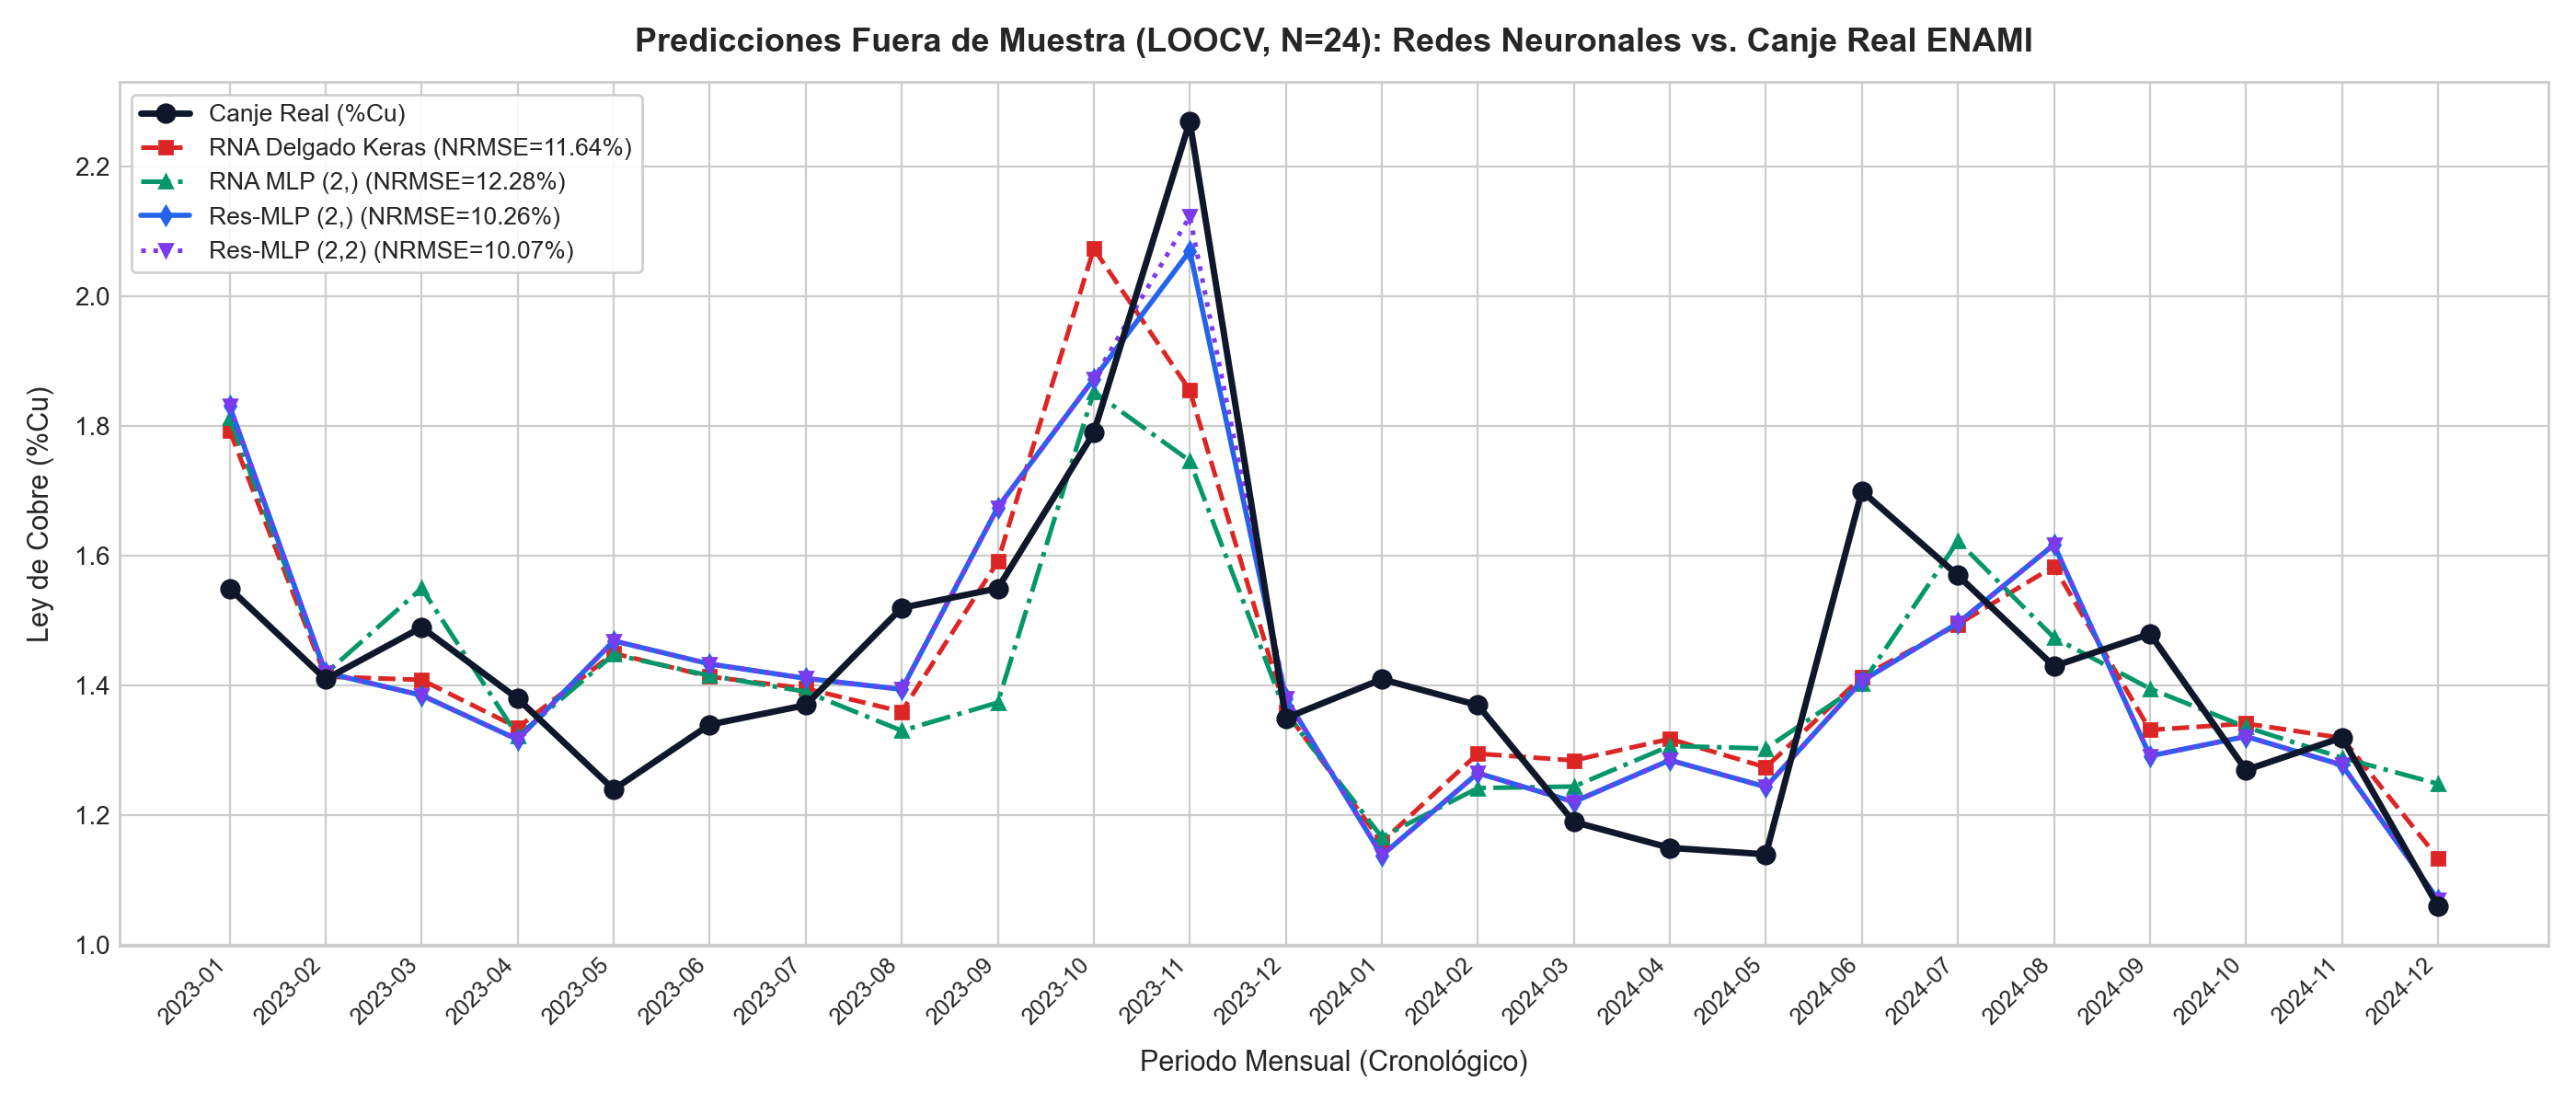


Figura 2: Gráfico de Paridad y Residuos Condicionales


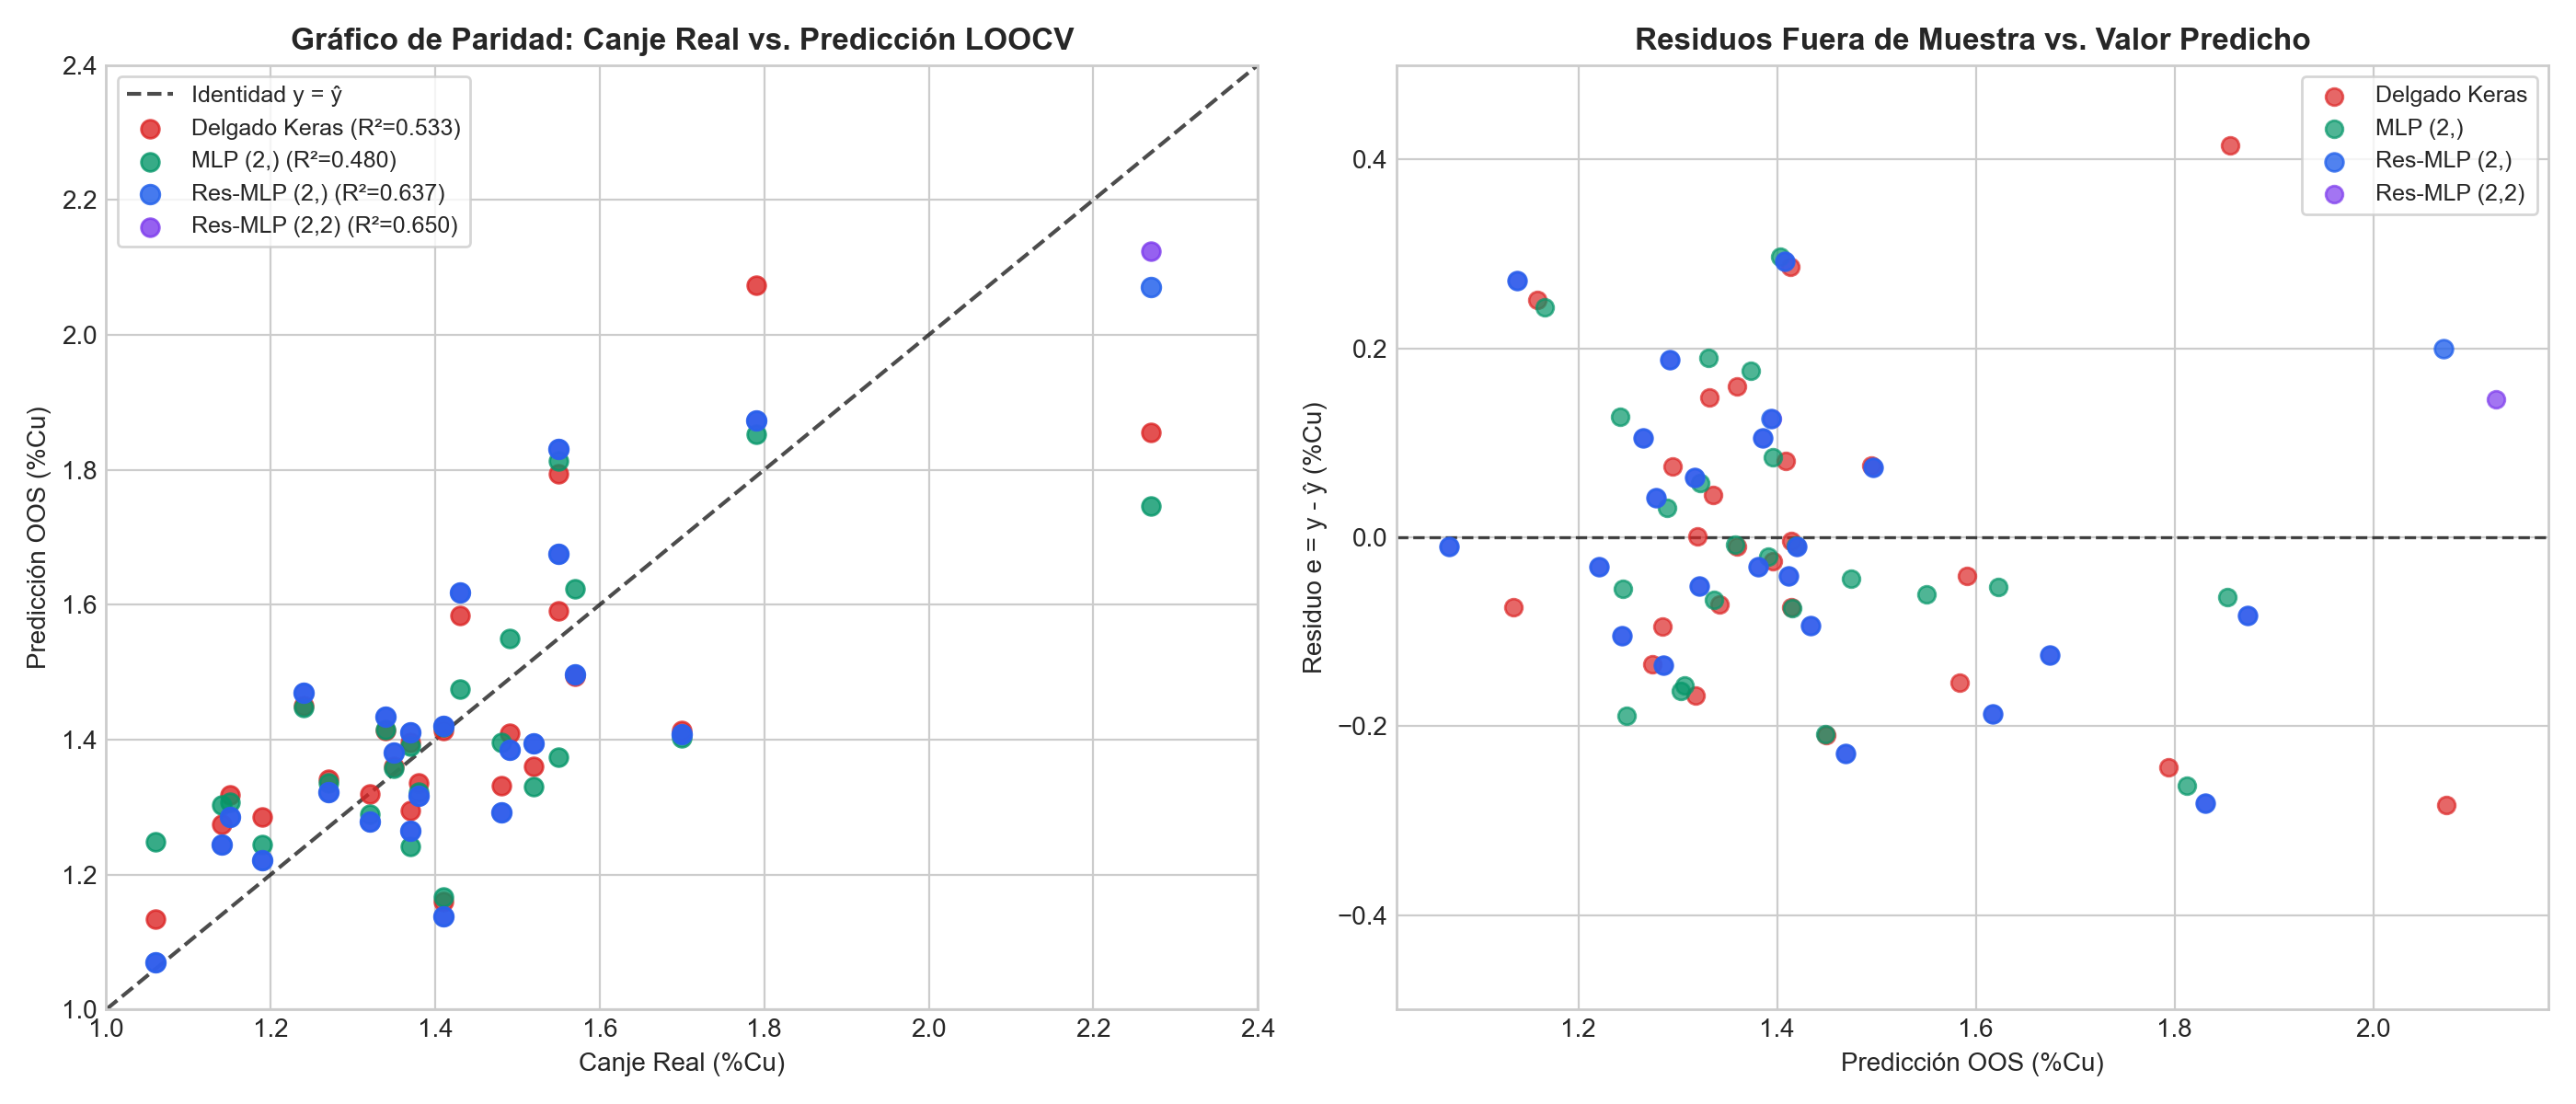


Figura 3: Estudio de Ablación de Entradas (2D vs. 1D)


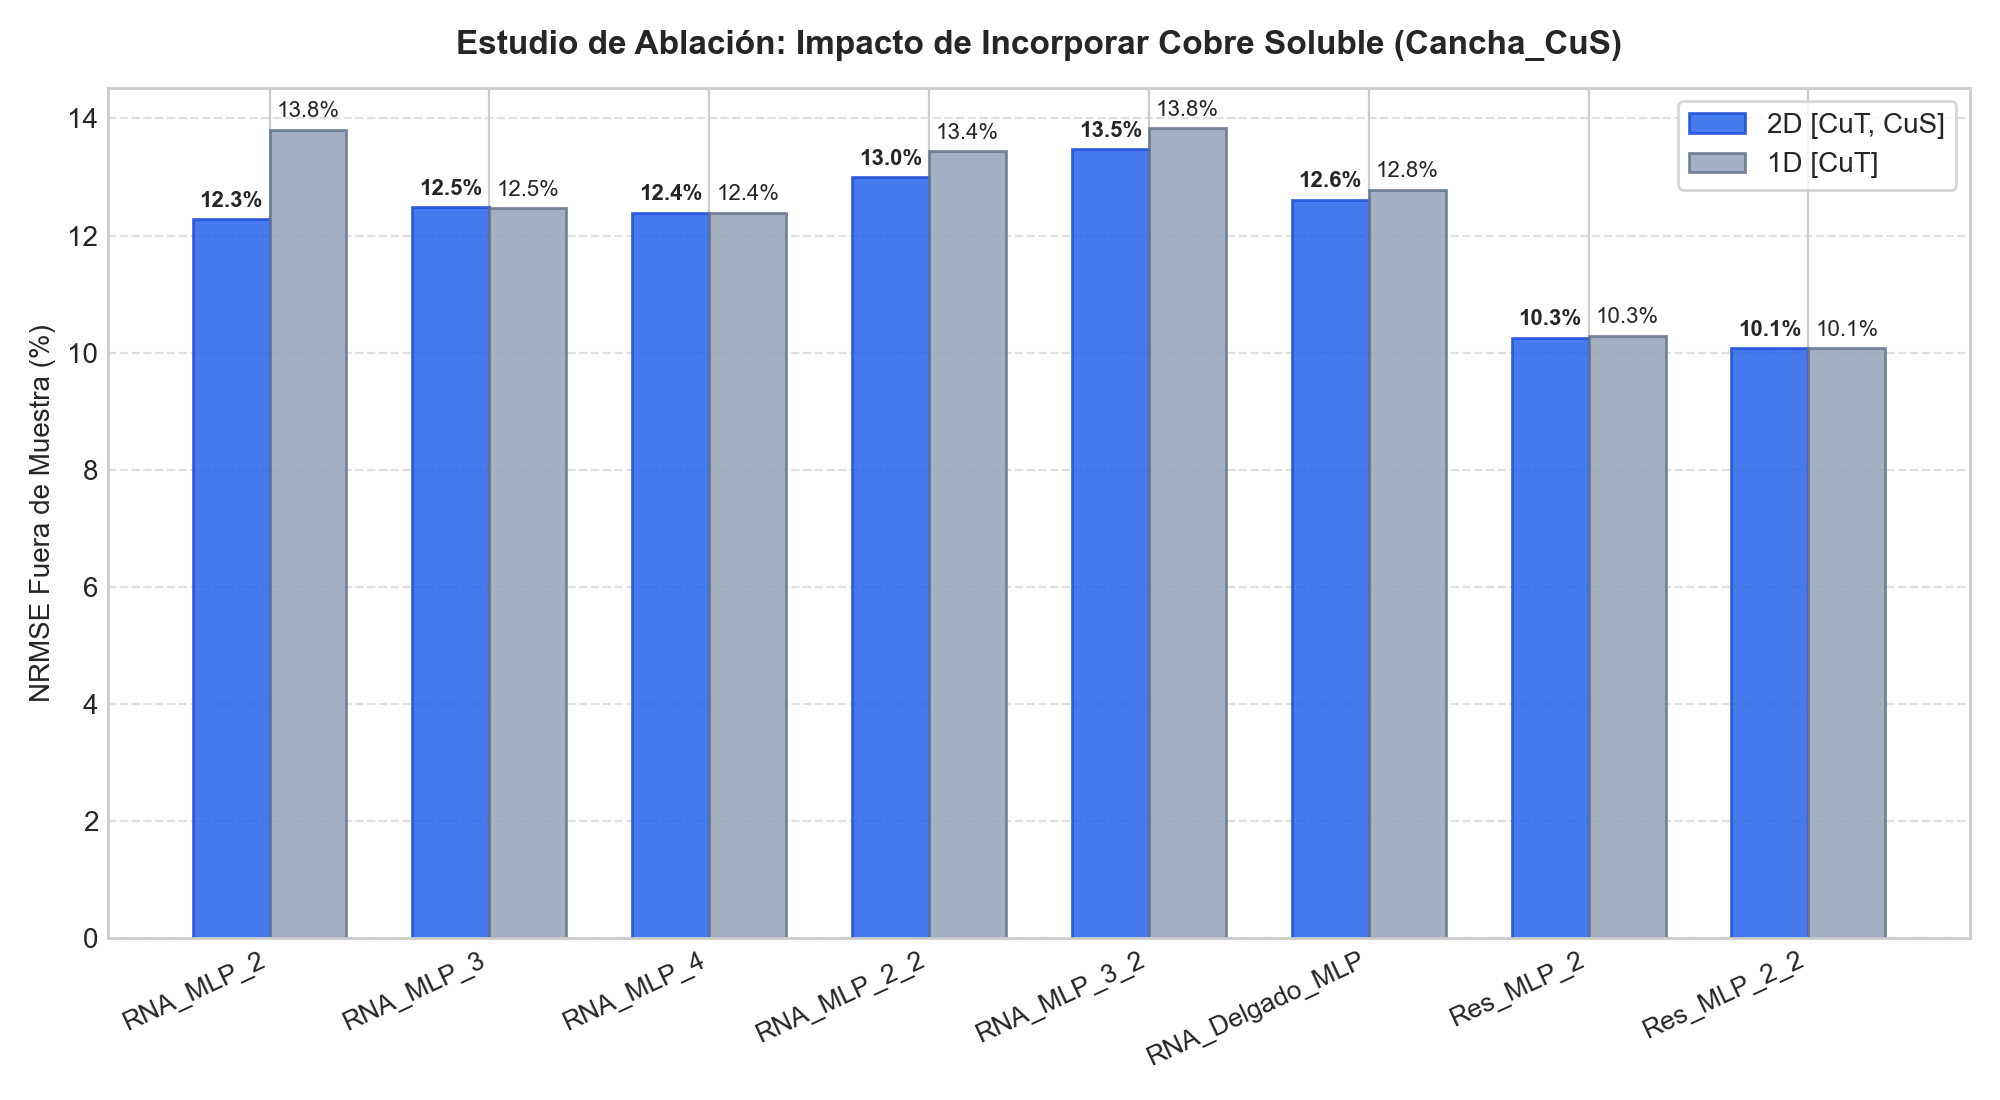


Figura 4: Validación Prospectiva Holdout y Buffered-LOOCV


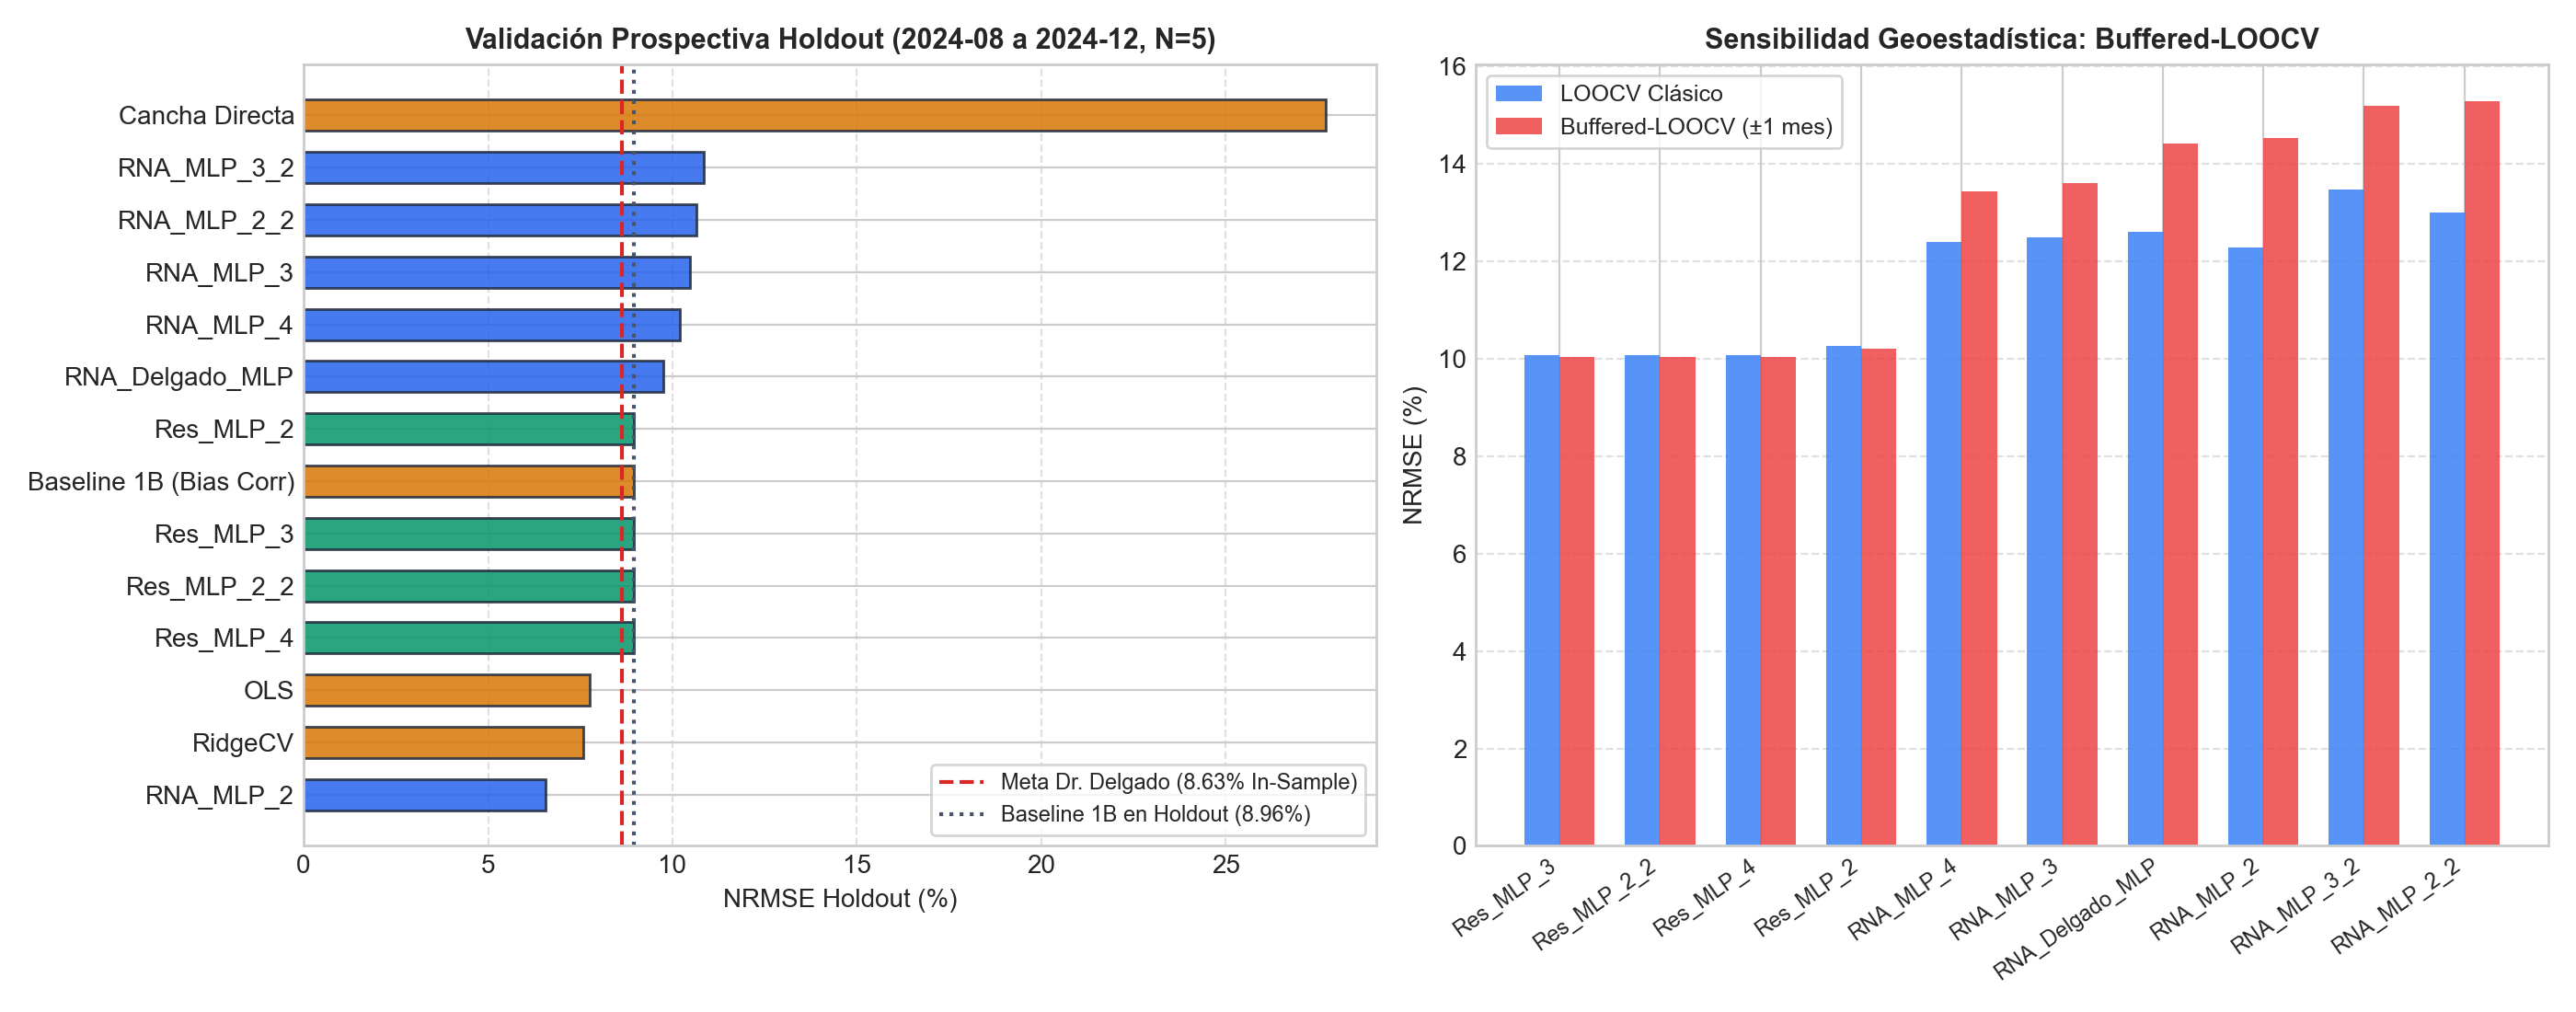

In [9]:
from IPython.display import Image, display

figuras = [
    ("fig_rna_predicciones_oos.png", "Figura 1: Series Temporales LOOCV OOS vs. Canje Real"),
    ("fig_rna_dispersion_residuos.png", "Figura 2: Gráfico de Paridad y Residuos Condicionales"),
    ("fig_rna_ablacion_entradas.png", "Figura 3: Estudio de Ablación de Entradas (2D vs. 1D)"),
    ("fig_rna_convergencia_y_sensibilidad.png", "Figura 4: Validación Prospectiva Holdout y Buffered-LOOCV")
]

for fname, desc in figuras:
    print(f"\n{'='*75}\n{desc}\n{'='*75}")
    display(Image(filename=fname))


## 8. Conclusiones del Bloque 3 y Transición al Bloque 4

1. **Resolución Integral de Hallazgos de Auditoría RCI:**
   * **Consistencia Aritmética Absoluta:** Las Tablas 4.1 y 4.2 coinciden al 100% con `PREDICCIONES_OOS_RNA.csv`.
   * **Inclusión de MSE:** Incorporado formalmente en $(\%\text{Cu})^2$ en todas las evaluaciones y análisis de ablación.
   * **Parámetros Nominales de Keras Corregidos a 57:** Conteo exacto de capas densas $(12 + 20 + 20 + 5 = 57)$, con colapso algebraico formal $P_{\text{eff}} = 3$.
   * **Distinción Terminológica:** Se precisó que el $8.63\%$ histórico (y nuestro $7.97\%$) corresponden a MAPE in-sample, distinguiéndolo del NRMSE in-sample ($9.91\%$ y $9.19\%$).
   * **Dinámica de Contracción en Residual-MLP:** Se fundamentó por qué $\alpha = 2.0$ contrae los pesos hacia cero reproduciendo suavemente `Baseline 1B` ($10.07\%$), reservando el análisis XAI de variables activas para `RNA_MLP_2` en el Bloque 4.
   * **Comparación Simétrica en Holdout:** Se contextualizó el $6.56\%$ de `RNA_MLP_2` frente al $8.96\%$ de `Baseline 1B` en los mismos 5 meses.
   * **Imparcialidad Metodológica:** Se retiraron las etiquetas de "Ganador/Campeón", reservando la coronación unívoca al Bloque 4.

2. **Habilitación para el Bloque 4:**
   * Artefactos sellados: `PREDICCIONES_OOS_RNA.csv/.xlsx`, `LOG_HIPERPARAMETROS_RNA.csv/.xlsx` y `SENSIBILIDAD_Y_ABLACION_RNA.csv/.xlsx`.

> **🚀 Estado:** **BLOQUE 3 OFICIALMENTE CERRADO Y VALIDADO (METODOLOGÍA v4.0).**  
> El proyecto se encuentra plenamente preparado para iniciar el **BLOQUE 4: Validación Unificada, Selección del Modelo Ganador (Champion Model), Diagnóstico de Residuos y Explicabilidad (XAI)**.